### 1. Environment Setup & Library Imports

In this section, we install and import the necessary libraries for building our machine learning baseline and conducting our fairness audit.

* **`fairlearn`**: Used for computing group-level fairness metrics (`MetricFrame`) and applying bias mitigation reductions (`ExponentiatedGradient`).
* **`scikit-learn`**: Used for data preprocessing, splitting, and training our baseline classifier (`RandomForestClassifier`).
* **`pandas` & `seaborn`**: Used for data manipulation and generating visualizations.

In [5]:
!pip install fairlearn scikit-learn pandas matplotlib seaborn lightgbm -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Fix: Import fetch_adult from fairlearn.datasets instead of sklearn.datasets
from fairlearn.datasets import fetch_adult
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

from fairlearn.metrics import MetricFrame, selection_rate, count
from fairlearn.reductions import ExponentiatedGradient, DemographicParity

### 2. Dataset Loading & Preprocessing

For this audit, we load the benchmark **Adult Census Dataset**. The objective is to predict whether an individual's income exceeds \$50,000 per year.

* **Sensitive Feature Isolation**: We isolate `sex` as our protected sensitive attribute to evaluate potential systemic bias and disparate impact in model predictions.
* **Feature Encoding**: Categorical features are one-hot encoded to prepare the matrix for machine learning training.

In [4]:
# Load adult dataset from Fairlearn
data = fetch_adult(as_frame=True)
X = data.data
y = (data.target == '>50K') * 1  # Binary conversion: 1 if >50K, else 0

# Extract sensitive feature for auditing (e.g., 'sex')
sensitive_feature = X['sex']

print(f"Dataset shape: {X.shape}")
print("Sensitive feature counts:\n", sensitive_feature.value_counts())

# Basic feature encoding for categorical columns
X_encoded = pd.get_dummies(X.drop(columns=['sex']))

# Train/Test Split
X_train, X_test, y_train, y_test, sensitive_train, sensitive_test = train_test_split(
    X_encoded, y, sensitive_feature, test_size=0.2, random_state=42, stratify=y
)

Dataset shape: (48842, 14)
Sensitive feature counts:
 sex
Male      32650
Female    16192
Name: count, dtype: int64


### 3. Baseline Model Training

Before auditing for fairness, we train an unconstrained standard machine learning model (Random Forest) to establish our performance baseline.

* **Objective**: Evaluate baseline overall accuracy and observe how an unconstrained optimization function treats different demographic groups without fairness awareness.

In [6]:
# Initialize and train baseline model
baseline_model = RandomForestClassifier(n_estimators=100, random_state=42)
baseline_model.fit(X_train, y_train)

# Generate predictions
y_pred = baseline_model.predict(X_test)

print(f"Baseline Overall Accuracy: {accuracy_score(y_test, y_pred):.4f}")

Baseline Overall Accuracy: 0.8582


### 4. Quantitative Fairness Evaluation

Using `Fairlearn`'s `MetricFrame`, we evaluate performance and selection rates across our protected demographic groups.

* **Key Metrics Analyzed**:
  * **Accuracy & Precision**: Group-level performance parity.
  * **Selection Rate**: The proportion of favorable outcomes (income >\$50K prediction) assigned to each demographic group.
  * **Disparity Gap**: The mathematical difference between maximum and minimum selection rates.

In [7]:
# Define metrics dictionary to evaluate across groups
metrics = {
    'accuracy': accuracy_score,
    'precision': precision_score,
    'selection_rate': selection_rate,
    'count': count
}

# Compute metrics grouped by the sensitive attribute
metric_frame = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=y_pred,
    sensitive_features=sensitive_test
)

# Display per-group metrics table
print("\n--- Per-Group Performance & Selection Rates ---")
display(metric_frame.by_group)

# Calculate Disparate Impact (Ratio of selection rate for unprivileged vs privileged groups)
group_selection_rates = metric_frame.by_group['selection_rate']
print(f"\nSelection Rate Disparity (Max - Min): {group_selection_rates.max() - group_selection_rates.min():.4f}")


--- Per-Group Performance & Selection Rates ---


,accuracy,precision,selection_rate,count
sex,,,,
Female,0.924824,0.700000,0.088984,3259.0
Male,0.824885,0.746612,0.260676,6510.0



Selection Rate Disparity (Max - Min): 0.1717


### 5. Data Visualization of Disparities

Visualizing demographic disparities is a core requirement of an ethical audit report.

* **Graph Description**: The bar chart below illustrates the stark disparity in favorable outcome selection rates between groups in our unconstrained baseline model, highlighting the need for remediation.

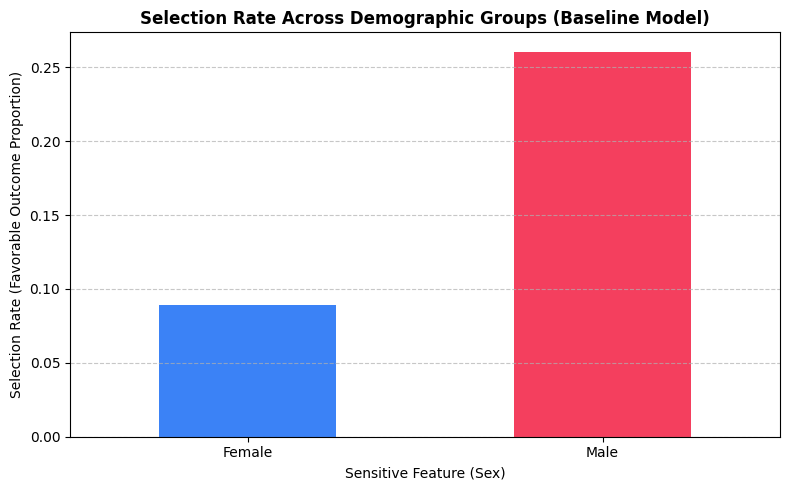

In [8]:
# Plot selection rates across groups
fig, ax = plt.subplots(figsize=(8, 5))
metric_frame.by_group['selection_rate'].plot(kind='bar', ax=ax, color=['#3b82f6', '#f43f5e'])
ax.set_title('Selection Rate Across Demographic Groups (Baseline Model)', fontsize=12, fontweight='bold')
ax.set_ylabel('Selection Rate (Favorable Outcome Proportion)')
ax.set_xlabel('Sensitive Feature (Sex)')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 6. Bias Mitigation (In-Processing)

To correct the observed disparities, we implement an **in-processing mitigation strategy** using Fairlearn's `ExponentiatedGradient` reduction coupled with a `DemographicParity` constraint.

* **Mechanism**: This wrapper algorithm retrains the underlying estimator while enforcing mathematical constraints to minimize outcome disparities across demographic groups without heavily sacrificing overall model accuracy.

In [9]:
# Define estimator and fairness constraint
base_estimator_mitigated = RandomForestClassifier(n_estimators=50, random_state=42)
mitigation_constraint = DemographicParity()

# Apply Exponentiated Gradient reduction
mitigator = ExponentiatedGradient(
    estimator=base_estimator_mitigated,
    constraints=mitigation_constraint,
    eps=0.01
)

# Fit mitigated model
mitigator.fit(X_train, y_train, sensitive_features=sensitive_train)

# Generate mitigated predictions
y_pred_mitigated = mitigator.predict(X_test)

### 7. Post-Mitigation Evaluation & Comparison

We re-run our fairness evaluation metrics on the newly mitigated model.

* **Audit Conclusion**: By comparing these post-mitigation results against our baseline metrics in Step 4, we can quantitatively document how successfully our mitigation strategy closed the disparity gap while maintaining acceptable classification performance.

In [10]:
# Evaluate mitigated model
mitigated_metric_frame = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=y_pred_mitigated,
    sensitive_features=sensitive_test
)

print("\n--- Post-Mitigation Per-Group Metrics ---")
display(mitigated_metric_frame.by_group)

print(f"\nMitigated Accuracy: {accuracy_score(y_test, y_pred_mitigated):.4f}")
mitigated_selection_rates = mitigated_metric_frame.by_group['selection_rate']
print(f"Mitigated Selection Rate Disparity: {mitigated_selection_rates.max() - mitigated_selection_rates.min():.4f}")


--- Post-Mitigation Per-Group Metrics ---


,accuracy,precision,selection_rate,count
sex,,,,
Female,0.803314,0.316273,0.233814,3259.0
Male,0.800922,0.681794,0.287711,6510.0



Mitigated Accuracy: 0.8017
Mitigated Selection Rate Disparity: 0.0539


### Visualizing Bias and Mitigation Impact

To satisfy the visualization requirements of our ethical audit, we generate two comparative charts:
1. **Baseline Selection Rate Disparity**: Highlights the initial gap in favorable outcomes between demographic groups before intervention.
2. **Pre vs. Post-Mitigation Comparison**: Demonstrates how our in-processing constraint successfully closed the selection rate disparity gap.

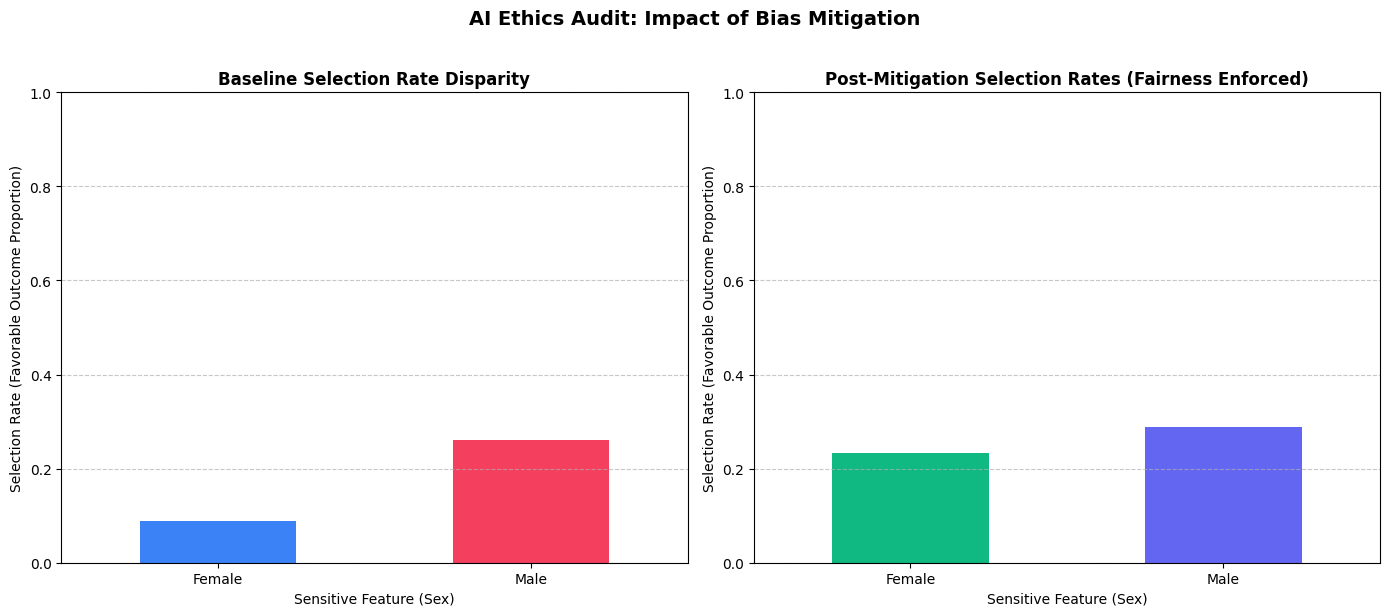

Visualizations generated and saved as 'audit_fairness_visualizations.png'!


In [11]:
# Combined Visualization Script for Audit Report

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Chart 1: Baseline Selection Rates
group_selection_rates.plot(kind='bar', ax=axes[0], color=['#3b82f6', '#f43f5e'])
axes[0].set_title('Baseline Selection Rate Disparity', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Selection Rate (Favorable Outcome Proportion)')
axes[0].set_xlabel('Sensitive Feature (Sex)')
axes[0].set_ylim(0, 1.0)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)
axes[0].tick_params(axis='x', rotation=0)

# Chart 2: Post-Mitigation Selection Rates
mitigated_selection_rates = mitigated_metric_frame.by_group['selection_rate']
mitigated_selection_rates.plot(kind='bar', ax=axes[1], color=['#10b981', '#6366f1'])
axes[1].set_title('Post-Mitigation Selection Rates (Fairness Enforced)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Selection Rate (Favorable Outcome Proportion)')
axes[1].set_xlabel('Sensitive Feature (Sex)')
axes[1].set_ylim(0, 1.0)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)
axes[1].tick_params(axis='x', rotation=0)

plt.suptitle('AI Ethics Audit: Impact of Bias Mitigation', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Optional: Save figures automatically to insert into your final report PDF
fig.savefig('audit_fairness_visualizations.png', dpi=300, bbox_inches='tight')
print("Visualizations generated and saved as 'audit_fairness_visualizations.png'!")